

```
Design a Customize Convolutional Neural Network (CNN) for Handwritten Digit
Classification with the following specifications:
a) Generate a CNN model with:
i. Two CNN hidden layers (Conv2D) of sizes 32, 64 followed by
ii. ReLU Activation and
iii. MaxPooling2D with Kernel size (3, 3), and Stride= (1,1)
b) Use Flatten Layers to convert the feature map into 1D with a Dense layer of size 64
followed by an output Dense Layer of size 10 with SoftMax Activation Function.
c) Display the numbers.
d) Display the Odd numbers only.
e) Use the MNIST database for training and testing and compare training accuracy Vs
testing accuracy by graph.
```



In [16]:
#Download mnist dataset
(x_train,y_train),(x_test,y_test)=mnist.load_data()

#Normalize dataset
x_train=x_train/255.0
x_test=x_test/255.0

x_train=x_train.reshape(-1,28,28,1)
x_test=x_test.reshape(-1,28,28,1)

#split validation set 15% from train dataset
x_train,x_val,y_train,y_val=train_test_split(
    x_train,
    y_train,
    test_size=0.15,
    shuffle=True,
    random_state=42,
    stratify=y_train
)

In [17]:
# a) Generate a CNN model with:
# i. Two CNN hidden layers (Conv2D) of sizes 32, 64 followed by
# ii. ReLU Activation and
# iii. MaxPooling2D with Kernel size (3, 3), and Stride= (1,1)
# b) Use Flatten Layers to convert the feature map into 1D with a Dense layer of size 64
# followed by an output Dense Layer of size 10 with SoftMax Activation Function.

model=Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(3,3),strides=(1,1)),

    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D(pool_size=(3,3),strides=(1,1)),

    Flatten(),

    Dense(64,activation='relu'),

    Dense(10,activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,657,930 (6.32 MB)

 Trainable params: 1,657,930 (6.32 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history=model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(x_val,y_val)
)

Epoch 1/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9615 - loss: 0.1245 - val_accuracy: 0.9773 - val_loss: 0.0685
Epoch 2/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9867 - loss: 0.0428 - val_accuracy: 0.9854 - val_loss: 0.0463
Epoch 3/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9902 - loss: 0.0311 - val_accuracy: 0.9890 - val_loss: 0.0427
Epoch 4/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9921 - loss: 0.0239 - val_accuracy: 0.9883 - val_loss: 0.0435
Epoch 5/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9948 - loss: 0.0167 - val_accuracy: 0.9877 - val_loss: 0.0460
Epoch 6/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9952 - loss: 0.0145 - val_accuracy: 0.9872 - val_loss: 0.0507
Epoch 7/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9954 - loss: 0.0141 - val_accuracy: 0.9878 - val_loss: 0.0484
Epoch 8/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9965 - loss: 0.0106 - val_accuracy: 


Validation Loss: 0.07264834642410278
Validation Accuracy: 0.988111138343811 

Test Loss: 0.049325332045555115
Test Accuracy: 0.989799976348877 



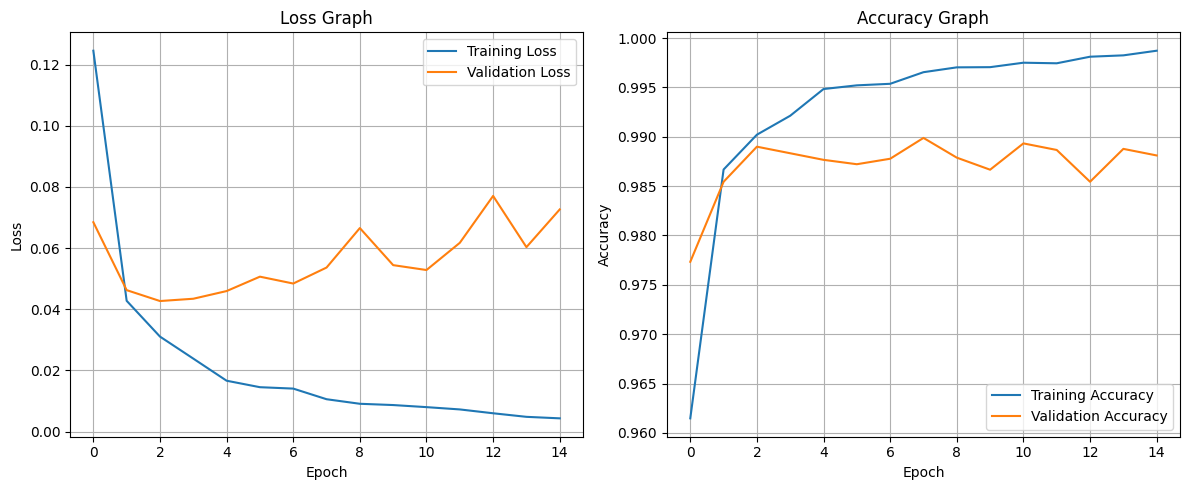

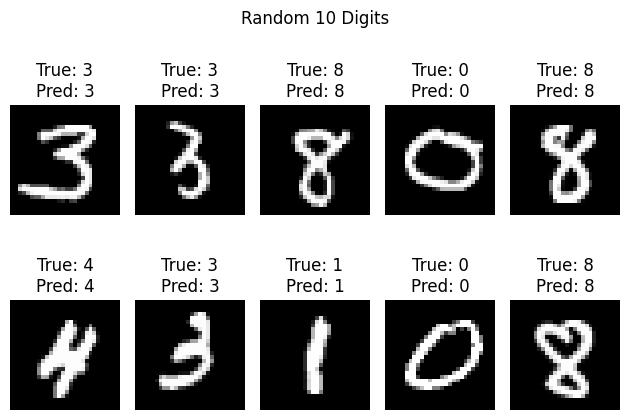

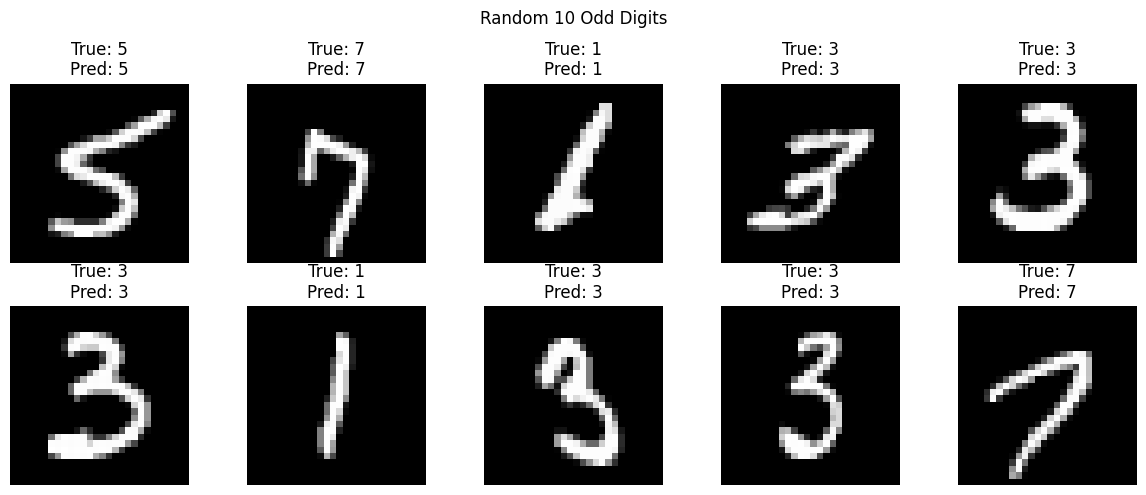

In [19]:
# c) Display the numbers.
# d) Display the Odd numbers only.
# e) Use the MNIST database for training and testing and compare training accuracy Vs
# testing accuracy by graph.

test_loss,test_accuracy=model.evaluate(
    x_test,
    y_test,
    verbose=0
)
val_loss=history.history['val_loss'][-1]
val_accuracy=history.history['val_accuracy'][-1]

print("\nValidation Loss:",val_loss)
print("Validation Accuracy:",val_accuracy,"\n")
print("Test Loss:",test_loss)
print("Test Accuracy:",test_accuracy,"\n")


# e) Use the MNIST database for training and testing and compare training accuracy Vs
# testing accuracy by graph.

plt.figure(figsize=(12,5))


plt.subplot(1,2,1)

plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Graph")
plt.legend()
plt.grid()



plt.subplot(1,2,2)

plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.plot(history.history['val_accuracy'],label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Graph")
plt.legend()
plt.grid()


plt.tight_layout()
plt.show()
print("\n")

# c) Display the numbers.
indices = np.random.choice(len(x_test), 10, replace=False)

for i, idx in enumerate(indices):
    image = x_test[idx].reshape(1, 28, 28, 1)
    prediction = np.argmax(model.predict(image, verbose=0))

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f"True: {y_test[idx]}\nPred: {prediction}")
    plt.axis('off')
plt.suptitle("Random 10 Digits")
plt.tight_layout()
plt.show()
print("\n")

# d) Display the Odd numbers only.
odd_indices = np.where(y_test % 2 != 0)[0]
indices = np.random.choice(odd_indices, 10, replace=False)

plt.figure(figsize=(12,5))

for i, idx in enumerate(indices):
    image = x_test[idx].reshape(1, 28, 28, 1)
    prediction = np.argmax(model.predict(image, verbose=0))

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f"True: {y_test[idx]}\nPred: {prediction}")
    plt.axis('off')

plt.suptitle("Random 10 Odd Digits")
plt.tight_layout()
plt.show()
